# PRÁCTICA 6 · APRENDIZAJE POR REFUERZO
# MARIO ROSELL · XIANG LIN

## TAREA 1. Sin resbalar.

In [37]:
import gymnasium as gym
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

entorno = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=False)

In [32]:
def elegir_accion(Q, estado, epsilon, rng):
    if rng.random() < epsilon: 
        return rng.integers(0,4)

    max_val = np.max(Q[estado])
    mejores = np.flatnonzero(Q[estado] == max_val)
    return rng.choice(mejores)


def entrenar(entorno, episodios, gamma=0.95, epsilon=1.0, alpha=1.0, semilla=0,
            alpha_dinamico=False, decrementar_epsilon=False, epsilon_min=0.01, tasa_decaimiento=0.9995):
    rng = np.random.default_rng(semilla)
    entorno.reset(seed=semilla)

    visitas = np.zeros((entorno.observation_space.n, entorno.action_space.n))
    Q = np.zeros((entorno.observation_space.n, entorno.action_space.n))
    recompensas = []
    for episodio in range(episodios):
        estado, _ = entorno.reset()
        fin, total = False, 0
        while not fin:
            accion = elegir_accion(Q, estado, epsilon, rng)
            estado2, r, terminado, truncado, _ = entorno.step(accion)
            fin = terminado or truncado

            if alpha_dinamico:
                visitas[estado, accion] += 1
                alpha = 1.0 / (1.0 + visitas[estado, accion])

            objetivo = r if terminado else r + gamma * np.max(Q[estado2])
            Q[estado, accion] = (1-alpha) * Q[estado, accion] + alpha * objetivo
            
            estado = estado2
            total += r
        recompensas.append(total)
        if decrementar_epsilon: epsilon = max(epsilon_min, epsilon * tasa_decaimiento)
    return Q, recompensas

def evaluar(entorno, Q, episodios=100):
    exitos = 0
    for _ in range(episodios):
        estado, _ = entorno.reset()
        fin = False
        while not fin:
            accion = np.argmax(Q[estado]) 
            estado2, r, terminado, truncado, _ = entorno.step(accion)
            fin = terminado or truncado
            if terminado and r == 1:
                exitos += 1
            estado = estado2
    return (exitos / episodios) * 100

FLECHAS = "←↓→↑"   # 0 = ←, 1 = ↓, 2 = →, 3 = ↑

def mostrar_politica(Q, entorno):
    mapa = entorno.unwrapped.desc.astype(str)   # 'S', 'F', 'H', 'G'
    filas, columnas = mapa.shape
    for f in range(filas):
        linea = []
        for c in range(columnas):
            s = f * columnas + c
            linea.append(mapa[f, c] if mapa[f, c] in "HG" else FLECHAS[int(np.argmax(Q[s]))])
        print(" ".join(linea))

def media_movil(recompensas, ventana=50):
    r = np.asarray(recompensas, dtype=float)
    return np.convolve(r, np.ones(ventana) / ventana, mode="valid")

In [35]:
Q_tabla, recompensas = entrenar(entorno, 1000)

porcentaje = evaluar(entorno, Q_tabla)
print(f"Porcentaje de éxito sin explorar: {porcentaje}%")

print("---POLITICA---")
mostrar_politica(Q_tabla, entorno)

print("---VALORES MÁXIMOS DE Q---")
max_q_cuadricula = np.max(Q_tabla, axis=1).reshape(4, 4)
print(np.round(max_q_cuadricula, 4))

Porcentaje de éxito sin explorar: 100.0%
---POLITICA---
↓ → ↓ ←
↓ H ↓ H
→ ↓ ↓ H
H → → G
---VALORES MÁXIMOS DE Q---
[[0.7738 0.8145 0.8574 0.8145]
 [0.8145 0.     0.9025 0.    ]
 [0.8574 0.9025 0.95   0.    ]
 [0.     0.95   1.     0.    ]]


**Convergencia del 100%:** El agente alcanza una tasa de éxito del 100% debido a que el entorno es completamente determinista (`is_slippery=False`), permitiendo que la tabla $Q$ converja de forma limpia hacia la política óptima tras suficientes episodios.

**Comportamiento del factor de descuento ($\gamma$):** Se observa que los valores máximos de la tabla $Q$ decrecen progresivamente a medida que nos alejamos de la casilla objetivo (`G`). Esto responde matemáticamente al factor de descuento ($\gamma = 0.95$), el cual penaliza las recompensas futuras frente a las inmediatas, reflejando el coste temporal en número de pasos hasta la meta.

## TAREA 2. Resbalando.

Notese que la función entrenar ya fue modificada originalmente para incluir alpha. Se incluye la parte opcional con el contador de visitados para modificar el alpha, la parte 5 de la tarea 2.

In [36]:
entorno_resbala = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=True)
porcentaje_ant = evaluar(entorno_resbala, Q_tabla, 100)

exitos_alpha1, exitos_alpha01, exitos_alphadin = [], [], []

for s in range(3):
    Q_resbala_a1, _ = entrenar(entorno_resbala, 10000, semilla=s, decrementar_epsilon=True)
    Q_resbala_a01, _ = entrenar(entorno_resbala, 10000, alpha= 0.1, semilla=s, decrementar_epsilon=True)
    Q_resbala_adin, _ = entrenar(entorno_resbala, 10000, semilla=s, decrementar_epsilon=True, alpha_dinamico=True)
    exitos_alpha1.append(evaluar(entorno_resbala, Q_resbala_a1, 1000))
    exitos_alpha01.append(evaluar(entorno_resbala, Q_resbala_a01, 1000))
    exitos_alphadin.append(evaluar(entorno_resbala, Q_resbala_adin, 1000))

media_alpha1, media_alpha01, media_alphadin = np.mean(exitos_alpha1), np.mean(exitos_alpha01), np.mean(exitos_alphadin)

tabla_resultados = pd.DataFrame({
    "Configuración": [
        "Política Tarea 1", 
        "Entrenado con α = 1.0", 
        "Entrenado con α = 0.1", 
        "Entrenado con α dinámico"
    ],
    "Porcentaje de Éxito Medio": [
        f"{porcentaje_ant:.2f}%", 
        f"{media_alpha1:.2f}%",
        f"{media_alpha01:.2f}%",
        f"{media_alphadin:.2f}%"
    ]
})

display(tabla_resultados)

,Configuración,Porcentaje de Éxito Medio
0,Política Tarea 1,5.00%
1,Entrenado con α = 1.0,0.00%
2,Entrenado con α = 0.1,69.40%
3,Entrenado con α dinámico,13.83%


**Fracaso de la política T.1 y $\alpha = 1.0$ (0% - 5% de éxito):** La política anterior fracasa porque fue optimizada para suelo firme; al introducir el deslizamiento, los desvíos imprevistos tiran al agente a los agujeros. Con $\alpha = 1.0$, el algoritmo actualiza el valor de $Q$ reemplazándolo por completo con la nueva estimación sin promediar, provocando que el ruido del entorno destruya el aprendizaje.

**Estabilidad con $\alpha = 0.1$ (~69.4% de éxito):** Una tasa de aprendizaje baja actúa como un filtro de suavizado temporal, permitiendo al agente promediar las experiencias a lo largo de múltiples trayectorias, mitigando el impacto del azar del hielo y consolidando una política robusta y conservadora.

**Limitación del $\alpha$ dinámico ($\alpha_n = \frac{1}{1 + \text{visitas}}$):** Aunque teóricamente reduce la varianza, en este entorno estocástico el parámetro $\alpha$ decrece con demasiada rapidez en las fases iniciales. Esto "congela" prematuramente los valores de la tabla $Q$ antes de que el agente haya explorado y asimilado las probabilidades reales del hielo, limitando su rendimiento final (~13.8%).

## TAREA 3. Experimento para la exploración.

In [47]:
Q_e0, rec_e0 = entrenar(entorno, 1000, semilla=s, epsilon=0)
Q_e01, rec_e01 = entrenar(entorno, 1000, semilla=s, epsilon=0.1)
Q_e05, rec_e05 = entrenar(entorno, 1000, semilla=s, epsilon=0.5)
Q_edecre, rec_edecre = entrenar(entorno, 1000, semilla=s, decrementar_epsilon=True)

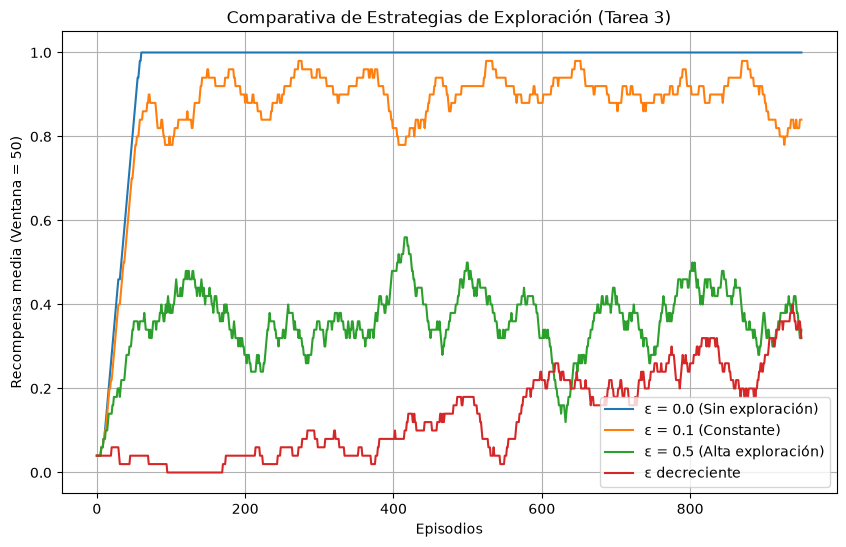

In [48]:
experimentos = {
    "ε = 0.0 (Sin exploración)": rec_e0,
    "ε = 0.1 (Constante)": rec_e01,
    "ε = 0.5 (Alta exploración)": rec_e05,
    "ε decreciente": rec_edecre
}

plt.figure(figsize=(10, 6))

for nombre, recompensas in experimentos.items():
    media_suavizada = media_movil(recompensas, ventana=50)
    plt.plot(media_suavizada, label=nombre)

plt.xlabel("Episodios")
plt.ylabel("Recompensa media (Ventana = 50)")
plt.title("Comparativa de Estrategias de Exploración (Tarea 3)")
plt.legend()
plt.grid(True)
plt.show()

In [49]:
modelos = {
    "ε = 0.0": Q_e0,
    "ε = 0.1": Q_e01,
    "ε = 0.5": Q_e05,
    "ε decreciente": Q_edecre
}

print("--- PORCENTAJES DE ÉXITO ---")
for nombre, Q_modelo in modelos.items():
    exito = evaluar(entorno, Q_modelo, episodios=100)
    print(f"Modelo {nombre}: {exito}%")

--- PORCENTAJES DE ÉXITO ---
Modelo ε = 0.0: 100.0%
Modelo ε = 0.1: 100.0%
Modelo ε = 0.5: 100.0%
Modelo ε decreciente: 100.0%


En el caso del desempate, cuando usamos argmax en vez de seleccionar aleatoriamente uno de los que tenga mejor puntuación, acabamos con un porcentaje de éxito del 0%.

Esto se debe a que se estanca en el inicio. Como argmax coje el primero de todos los elementos que sean máximos, el entreno pasa siempre por el mismo camino e impide una exploración por otros caminos, empeorando enormemente la solución. 

In [50]:
def elegir_accion_argmax_fijo(Q, estado, epsilon, rng):
    if rng.random() < epsilon: 
        return rng.integers(0, 4)
    return int(np.argmax(Q[estado])) 

def entrenar_con_argmax_fijo(entorno, episodios, gamma=0.95, epsilon=0.1, alpha=1.0, semilla=0):
    rng = np.random.default_rng(semilla)
    entorno.reset(seed=semilla)
    
    Q = np.zeros((entorno.observation_space.n, entorno.action_space.n))
    recompensas = []
    
    for episodio in range(episodios):
        estado, _ = entorno.reset()
        fin, total = False, 0
        while not fin:
            # Usamos nuestra nueva función de elección de acción
            accion = elegir_accion_argmax_fijo(Q, estado, epsilon, rng)
            estado2, r, terminado, truncado, _ = entorno.step(accion)
            fin = terminado or truncado

            objetivo = r if terminado else r + gamma * np.max(Q[estado2])
            Q[estado, accion] = (1 - alpha) * Q[estado, accion] + alpha * objetivo
            
            estado = estado2
            total += r
        recompensas.append(total)
        
    return Q, recompensas

Q_fijo, rec_fijo = entrenar_con_argmax_fijo(entorno, 1000, semilla=0)
exito_fijo = evaluar(entorno, Q_fijo, episodios=100)

print(f"Porcentaje de éxito con desempate fijo (np.argmax): {exito_fijo}%")

Porcentaje de éxito con desempate fijo (np.argmax): 0.0%


**Comportamiento de $\varepsilon = 0.0$ (Explotación pura):** Aunque teóricamente no explora, el rendimiento óptimo inicial se debe a un artefacto técnico del desempate: en el primer episodio, al estar la tabla $Q$ a ceros, se fuerza un desempate aleatorio (`np.flatnonzero`), lo que permite al agente hallar la meta de manera fortuita. Al ser un entorno determinista, explota esa ruta de inmediato y estabiliza su recompensa al máximo.

**Epsilon constante alto ($\varepsilon = 0.5$) vs. bajo ($\varepsilon = 0.1$):** Un valor elevado de $\varepsilon$ fuerza al agente a tomar acciones aleatorias de forma continuada, generando oscilaciones y un aprendizaje más ineficiente debido a caídas constantes en los agujeros. Tasas moderadas o decrecientes logran un balance óptimo entre la fase de descubrimiento inicial y la explotación posterior.

## TAREA 4 · Preguntas para la memoria

### 1. En la tarea 1, ¿por qué los valores de Q son más bajos cuanto más lejos está la casilla de la meta? ¿Qué papel tiene $\gamma$?
Como ya hemos observado previamente, los valores máximos de la tabla $Q$ decrecen de forma progresiva a medida que el agente se aleja de la casilla objetivo (`G`). 
Esto ocurre debido al **factor de descuento ($\gamma = 0.95$)**, el cual reduce matemáticamente el valor de las recompensas futuras en comparación con las inmediatas.
De este modo, $\gamma$ actúa reflejando el coste temporal: un camino más largo implica más pasos y, por tanto, una recompensa descontada menor al propagarse hacia atrás desde la meta. 

### 2. En la tarea 2, ¿por qué la política aprendida sin resbalar funciona mal en el lago resbaladizo? ¿Por qué $\alpha = 1$ aprende peor que $\alpha = 0,1$ cuando hay azar?
La política optimizada para suelo firme fracasa en el entorno resbaladizo porque los desvíos imprevistos provocados por el hielo terminan arrastrando al agente hacia los agujeros (`H`).
Con **$\alpha = 1.0$**, el algoritmo sustituye por completo el valor anterior de $Q$ con la nueva estimación sin aplicar ningún promedio, lo que hace que el ruido estocástico del entorno destruya el proceso de aprendizaje.
Por el contrario, **$\alpha = 0.1$** actúa como un filtro de suavizado temporal que permite promediar experiencias a lo largo de múltiples trayectorias, mitigando el impacto del azar y consolidando una política mucho más robusta.

### 3. En la tarea 3, ¿qué se pierde durante el entrenamiento por explorar mucho ($\varepsilon = 0,5$)? ¿Y qué ventaja tiene el $\varepsilon$ decreciente?
Un valor elevado de exploración ($\varepsilon = 0.5$) obliga al agente a tomar decisiones aleatorias de forma continuada, lo que provoca ineficiencia, oscilaciones severas en las recompensas y caídas constantes en los agujeros durante el entrenamiento.
El uso de un **$\varepsilon$ decreciente** combina lo mejor de dos mundos: permite una exploración intensa en las fases iniciales para descubrir el entorno y reduce progresivamente la aleatoriedad para dar paso a la explotación eficiente de la política óptima ya aprendida.

### 4. Explica lo que ha pasado en el paso 4 de la tarea 3 (el desempate). Relaciónalo con que en FrozenLake las recompensas son dispersas.
Al sustituir el desempate aleatorio por un `np.argmax` estricto con la tabla a ceros, el porcentaje de éxito cae estrepitosamente al **0%** porque el agente queda estancado en el inicio sin explorar caminos alternativos.
Dado que en FrozenLake las recompensas son dispersas (solo se premia con 1 al llegar a la meta y 0 en el resto), si el desempate es determinista, el agente siempre repite la misma trayectoria inicial nula y nunca descubre la meta de forma fortuita, impidiendo que la señal de refuerzo se propague por la tabla $Q$.

### 5. Pensando en el concurso: si el lago fuera mucho más grande, ¿qué cambiarías de tu agente para que aprendiera más rápido? (Pista: T6.3, aceleración del aprendizaje.)
Si el entorno aumentara considerablemente de tamaño, el enfoque tabular clásico sufriría la maldición de la dimensionalidad y el problema de las recompensas dispersas se agravaría de forma extrema. Para acelerar el aprendizaje se podrían adoptar las siguientes estrategias:
* **Model-based RL / Dyna-Q:** Permitir que el agente aprenda un modelo interno de las transiciones del entorno para simular y planificar experiencias adicionales sin necesidad de interactuar constantemente con el mundo real.
* **Aproximación de funciones (Deep Q-Networks - DQN):** Sustituir la tabla $Q$ por una red neuronal capaz de generalizar el valor de los estados en espacios de gran escala.
* **Modelado de recompensas guiadas (*Reward Shaping*):** Incorporar recompensas intermedias o heurísticas basadas en la distancia Manhattan hacia la meta para guiar al agente de forma más efectiva en las fases iniciales de exploración.

### 5. Pensando en el concurso: si el lago fuera mucho más grande, ¿qué cambiarías de tu agente para que aprendiera más rápido? (Pista: T6.3, aceleración del aprendizaje.)
Si el entorno fuera mucho más grande, el aprendizaje tabular clásico se volvería extremadamente lento debido a la maldición de la dimensionalidad y al problema de las recompensas dispersas (donde la gran mayoría de las transiciones producen una recompensa de 0 y solo unas pocas dan información directa). Para acelerar el proceso de aprendizaje y escalar el modelo, aplicaríamos las siguientes estrategias vistas en el Tema 6.3:

* **Actualización hacia atrás:** En lugar de actualizar únicamente el último paso del episodio, se registra el histórico completo de pares estado-acción recorridos y se actualizan todos ellos recorriendo la secuencia desde el final hasta el principio. Esto evita que un episodio largo actualice un único valor y acelera considerablemente la propagación de la recompensa.
* **Re-entrenado:** Implementar un mecanismo de revisión iterativa (mediante colas o pilas) que actualice de forma propagada los valores $\hat{Q}$ de los estados antecesores cada vez que se modifique un estado sucesor del que dependen, logrando que la tabla sea consistente de manera mucho más rápida.
* **Mecanismos de generalización (Aproximación de funciones):** Sustituir la tabla explícita por un modelo de aproximación de funciones (como redes neuronales, dando lugar al aprendizaje por refuerzo profundo). Esto permite que el agente actúe basándose en los vectores de características del entorno (por ejemplo, proximidad a paredes o hielo) en lugar de tratar cada estado como un símbolo atómico independiente, permitiendo escalar a espacios masivos o continuos.